In [1]:
import time
import math
import sys
import os
import random
from tqdm import tqdm
import shap
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import minmax_scale
from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder,
    MinMaxScaler,
    RobustScaler,
)
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import VotingRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from xgboost import XGBClassifier, XGBRegressor, plot_importance
from catboost import CatBoostClassifier, CatBoostRegressor
import optuna
import pandas_profiling
from sklearn.impute import SimpleImputer

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA

from scipy.stats.mstats import winsorize
import mlflow

`import pandas_profiling` is going to be deprecated by April 1st. Please use `import ydata_profiling` instead.


In [ ]:
import tensorflow as tf
import tensorflow_addons as tfa
from tensorflow_addons.metrics import RSquare
from tensorflow.keras.optimizers import *
import keras
import keras.backend as K
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation, BatchNormalization
from tensorflow.keras.metrics import *
from keras import backend
from keras.utils.vis_utils import plot_model
from keras.callbacks import (
    Callback,
    ModelCheckpoint,
    EarlyStopping,
    CSVLogger,
    ReduceLROnPlateau,
)
import autokeras as ak
import mitosheet

In [2]:
warnings.filterwarnings("ignore")
np.random.seed(42)

<h1 style="font-size:40px;"> <center> Data Reading </center> </h1>

In [3]:
survey = pd.read_csv("data/survey.csv")
survey

,id,maritalstatus,college,postcollege,highschool,primary,male,female,ozelsektor,kamu,...,mean_risk,cevap1_puan,cevap2_puan,cevap3_puan,cevap4_puan,cevap5_puan,cevap6_puan,cevap7_puan,risktotalpuan,riskprofil
0,201,0.0,1,0,0,0,0,1,1,0,...,5.125000,3,1.0,6.0,6.0,3.0,2.0,3.0,24.0,2.0
1,245,0.0,0,0,0,1,1,0,1,0,...,5.904167,9,2.0,9.0,9.0,5.0,3.0,3.0,40.0,4.0
2,570,1.0,0,0,1,0,1,0,1,0,...,6.500000,3,2.0,2.0,3.0,3.0,3.0,4.0,20.0,2.0
3,734,1.0,1,0,0,0,0,1,0,0,...,6.171875,6,0.0,6.0,9.0,5.0,3.0,3.0,32.0,2.0
4,850,0.0,1,0,0,0,1,0,1,0,...,5.375000,9,2.0,2.0,3.0,2.0,2.0,3.0,23.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91476,18062827,1.0,0,0,1,0,1,0,1,0,...,4.045096,6,0.0,4.0,3.0,3.0,3.0,3.0,22.0,2.0
91477,18063837,1.0,1,0,0,0,1,0,0,0,...,3.976786,9,1.0,2.0,3.0,2.0,2.0,3.0,22.0,2.0
91478,18064023,1.0,1,0,0,0,0,1,0,1,...,5.575000,3,2.0,4.0,6.0,3.0,5.0,3.0,26.0,2.0
91479,18064420,1.0,0,0,0,1,1,0,1,0,...,4.000000,3,0.0,2.0,0.0,0.0,0.0,0.0,5.0,1.0


<h1 style="font-size:40px;"> <center> EDA </center> </h1>

In [5]:
profile = pandas_profiling.ProfileReport(survey, title="Survey Data Exploration")
profile.to_file(output_file="Survey Data Profile Output.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

KeyboardInterrupt: 

<IPython.core.display.Javascript object>

In [5]:
mitosheet.sheet()

<IPython.core.display.Javascript object>

<h1 style="font-size:40px;"> <center> Data Preprocessing  </center> </h1>

In [4]:
# survey.fillna(survey.mode().iloc[0], inplace=True)
survey.fillna(survey.mean(), inplace=True)
survey

,id,maritalstatus,college,postcollege,highschool,primary,male,female,ozelsektor,kamu,...,mean_risk,cevap1_puan,cevap2_puan,cevap3_puan,cevap4_puan,cevap5_puan,cevap6_puan,cevap7_puan,risktotalpuan,riskprofil
0,201,0.0,1,0,0,0,0,1,1,0,...,5.125000,3,1.0,6.0,6.0,3.0,2.0,3.0,24.0,2.0
1,245,0.0,0,0,0,1,1,0,1,0,...,5.904167,9,2.0,9.0,9.0,5.0,3.0,3.0,40.0,4.0
2,570,1.0,0,0,1,0,1,0,1,0,...,6.500000,3,2.0,2.0,3.0,3.0,3.0,4.0,20.0,2.0
3,734,1.0,1,0,0,0,0,1,0,0,...,6.171875,6,0.0,6.0,9.0,5.0,3.0,3.0,32.0,2.0
4,850,0.0,1,0,0,0,1,0,1,0,...,5.375000,9,2.0,2.0,3.0,2.0,2.0,3.0,23.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91476,18062827,1.0,0,0,1,0,1,0,1,0,...,4.045096,6,0.0,4.0,3.0,3.0,3.0,3.0,22.0,2.0
91477,18063837,1.0,1,0,0,0,1,0,0,0,...,3.976786,9,1.0,2.0,3.0,2.0,2.0,3.0,22.0,2.0
91478,18064023,1.0,1,0,0,0,0,1,0,1,...,5.575000,3,2.0,4.0,6.0,3.0,5.0,3.0,26.0,2.0
91479,18064420,1.0,0,0,0,1,1,0,1,0,...,4.000000,3,0.0,2.0,0.0,0.0,0.0,0.0,5.0,1.0


In [5]:
survey.isna().sum().sum()

0

In [6]:
X = survey.loc[:, "maritalstatus":"katkipayi"]
X

,maritalstatus,college,postcollege,highschool,primary,male,female,ozelsektor,kamu,emekli,...,cevap2,cevap3,cevap4,cevap5,cevap6,cevap7,cevap8,gelir,age,katkipayi
0,0.0,1,0,0,0,0,1,1,0,0,...,2.0,4.0,3.0,3.0,2.0,3.0,2.0,20263.3850,45.000000,0.00000
1,0.0,0,0,0,1,1,0,1,0,0,...,3.0,5.0,4.0,4.0,3.0,3.0,2.0,12823.4160,26.833334,1633.33340
2,1.0,0,0,1,0,1,0,1,0,0,...,3.0,2.0,2.0,3.0,3.0,4.0,1.0,12835.6600,39.500000,366.00000
3,1.0,1,0,0,0,0,1,0,0,0,...,1.0,4.0,4.0,4.0,3.0,3.0,2.0,12313.9190,42.500000,270.00000
4,0.0,1,0,0,0,1,0,1,0,0,...,3.0,2.0,2.0,2.0,2.0,3.0,2.0,0.0000,32.500000,0.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91476,1.0,0,0,1,0,1,0,1,0,0,...,1.0,3.0,2.0,3.0,3.0,3.0,1.0,8189.1172,39.487179,0.00000
91477,1.0,1,0,0,0,1,0,0,0,0,...,2.0,2.0,2.0,2.0,2.0,3.0,2.0,25720.0490,32.166664,450.00000
91478,1.0,1,0,0,0,0,1,0,1,0,...,3.0,3.0,3.0,3.0,4.0,3.0,2.0,25724.7560,49.250000,341.75000
91479,1.0,0,0,0,1,1,0,1,0,0,...,1.0,2.0,1.0,1.0,1.0,1.0,2.0,11658.4700,37.000000,100.00000


In [7]:
y = survey["mean_risk"]
y

0        5.125000
1        5.904167
2        6.500000
3        6.171875
4        5.375000
           ...   
91476    4.045096
91477    3.976786
91478    5.575000
91479    4.000000
91480    4.978785
Name: mean_risk, Length: 91481, dtype: float64

<h1 style="font-size:40px;"> <center> Scaling  </center> </h1>

In [14]:
s_scaler = StandardScaler()
mm_scaler = MinMaxScaler()
r_scaler = RobustScaler()

In [ ]:
X = survey.loc[:, "maritalstatus":"katkipayi"]
df = r_scaler.fit_transform(X)
df = pd.DataFrame(df, columns=X.columns)
X = df
X

In [15]:
X = survey.loc[:, "maritalstatus":"katkipayi"]
df = mm_scaler.fit_transform(X)
df = pd.DataFrame(df, columns=X.columns)
X = df
X

,maritalstatus,college,postcollege,highschool,primary,male,female,ozelsektor,kamu,emekli,...,cevap2,cevap3,cevap4,cevap5,cevap6,cevap7,cevap8,gelir,age,katkipayi
0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.25,0.75,0.666667,0.666667,0.333333,0.50,1.0,0.058065,0.335404,0.209446
1,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.50,1.00,1.000000,1.000000,0.666667,0.50,1.0,0.036745,0.109731,0.243824
2,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.50,0.25,0.333333,0.666667,0.666667,0.75,0.0,0.036781,0.267081,0.217150
3,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.00,0.75,1.000000,1.000000,0.666667,0.50,1.0,0.035286,0.304348,0.215129
4,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.50,0.25,0.333333,0.333333,0.333333,0.50,1.0,0.000000,0.180124,0.209446
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91476,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.00,0.50,0.333333,0.666667,0.666667,0.50,0.0,0.023466,0.266921,0.209446
91477,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.25,0.25,0.333333,0.333333,0.333333,0.50,1.0,0.073701,0.175983,0.218918
91478,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.50,0.50,0.666667,0.666667,1.000000,0.50,1.0,0.073714,0.388199,0.216639
91479,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.00,0.25,0.000000,0.000000,0.000000,0.00,1.0,0.033407,0.236025,0.211551


In [70]:
X = survey.loc[:, "maritalstatus":"katkipayi"]
df = s_scaler.fit_transform(X)
df = pd.DataFrame(df, columns=X.columns)
X = df
X

,maritalstatus,college,postcollege,highschool,primary,male,female,ozelsektor,kamu,emekli,...,cevap2,cevap3,cevap4,cevap5,cevap6,cevap7,cevap8,gelir,age,katkipayi
0,-1.566260,0.895810,-0.272304,-0.645783,-0.247019,-1.446496,1.446496,0.716019,-0.350876,-0.217854,...,-0.336925,0.782205,0.434168,0.276288,-0.656349,-0.282974,0.589362,0.049373,0.603592,-0.453103
1,-1.566260,-1.116309,-0.272304,-0.645783,4.048274,0.691326,-0.691326,0.716019,-0.350876,-0.217854,...,0.663446,1.650722,1.459100,1.648966,0.544836,-0.282974,0.589362,-0.241794,-1.319002,1.860159
2,0.639036,-1.116309,-0.272304,1.548507,-0.247019,0.691326,-0.691326,0.716019,-0.350876,-0.217854,...,0.663446,-0.954831,-0.590765,0.276288,0.544836,0.651188,-1.851942,-0.241315,0.021522,0.065256
3,0.639036,0.895810,-0.272304,-0.645783,-0.247019,-1.446496,1.446496,-1.396612,-0.350876,-0.217854,...,-1.337295,0.782205,1.459100,1.648966,0.544836,-0.282974,0.589362,-0.261733,0.339015,-0.070707
4,-1.566260,0.895810,-0.272304,-0.645783,-0.247019,0.691326,-0.691326,0.716019,-0.350876,-0.217854,...,0.663446,-0.954831,-0.590765,-1.096390,-0.656349,-0.282974,0.589362,-0.743644,-0.719294,-0.453103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91476,0.639036,-1.116309,-0.272304,1.548507,-0.247019,0.691326,-0.691326,0.716019,-0.350876,-0.217854,...,-1.337295,-0.086313,-0.590765,0.276288,0.544836,-0.282974,-1.851942,-0.423159,0.020165,-0.453103
91477,0.639036,0.895810,-0.272304,-0.645783,-0.247019,0.691326,-0.691326,-1.396612,-0.350876,-0.217854,...,-0.336925,-0.954831,-0.590765,-1.096390,-0.656349,-0.282974,0.589362,0.262922,-0.754571,0.184224
91478,0.639036,0.895810,-0.272304,-0.645783,-0.247019,-1.446496,1.446496,-1.396612,2.850010,-0.217854,...,0.663446,-0.086313,0.434168,0.276288,1.746022,-0.282974,0.589362,0.263106,1.053373,0.030911
91479,0.639036,-1.116309,-0.272304,-0.645783,4.048274,0.691326,-0.691326,0.716019,-0.350876,-0.217854,...,-1.337295,-0.954831,-1.615698,-2.469069,-1.857534,-2.151298,0.589362,-0.287384,-0.243055,-0.311475


<h1 style="font-size:40px;"> <center> FEATURE SELECTION  </center> </h1>

In [60]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression, mutual_info_regression

In [71]:
fs = SelectKBest(score_func=mutual_info_regression, k=15)
X_selected = fs.fit_transform(X, y)
X = pd.DataFrame(X_selected, columns=X.columns[:15])

In [72]:
X

,maritalstatus,college,postcollege,highschool,primary,male,female,ozelsektor,kamu,emekli,isdiger,cevap1,cevap2,cevap3,cevap4
0,-1.566260,0.895810,-0.645783,-0.247019,-0.936356,-0.336925,0.782205,0.434168,0.276288,-0.656349,-0.282974,0.589362,0.049373,0.603592,-0.453103
1,-1.566260,-1.116309,-0.645783,4.048274,0.984374,0.663446,1.650722,1.459100,1.648966,0.544836,-0.282974,0.589362,-0.241794,-1.319002,1.860159
2,0.639036,-1.116309,1.548507,-0.247019,-0.936356,0.663446,-0.954831,-0.590765,0.276288,0.544836,0.651188,-1.851942,-0.241315,0.021522,0.065256
3,0.639036,0.895810,-0.645783,-0.247019,0.024009,-1.337295,0.782205,1.459100,1.648966,0.544836,-0.282974,0.589362,-0.261733,0.339015,-0.070707
4,-1.566260,0.895810,-0.645783,-0.247019,0.984374,0.663446,-0.954831,-0.590765,-1.096390,-0.656349,-0.282974,0.589362,-0.743644,-0.719294,-0.453103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91476,0.639036,-1.116309,1.548507,-0.247019,0.024009,-1.337295,-0.086313,-0.590765,0.276288,0.544836,-0.282974,-1.851942,-0.423159,0.020165,-0.453103
91477,0.639036,0.895810,-0.645783,-0.247019,0.984374,-0.336925,-0.954831,-0.590765,-1.096390,-0.656349,-0.282974,0.589362,0.262922,-0.754571,0.184224
91478,0.639036,0.895810,-0.645783,-0.247019,-0.936356,0.663446,-0.086313,0.434168,0.276288,1.746022,-0.282974,0.589362,0.263106,1.053373,0.030911
91479,0.639036,-1.116309,-0.645783,4.048274,-0.936356,-1.337295,-0.954831,-1.615698,-2.469069,-1.857534,-2.151298,0.589362,-0.287384,-0.243055,-0.311475


<h1 style="font-size:40px;"> <center> PCA & LDA  </center> </h1>

In [43]:
X = survey.loc[:, "maritalstatus":"katkipayi"]
df = s_scaler.fit_transform(X)
pca = PCA(n_components=20)
tdf = pca.fit_transform(df)
X = pd.DataFrame(tdf, columns=X.columns[:20])
exp_var_pca = pca.explained_variance_ratio_
sum(exp_var_pca)

0.9999999999999999

<h1 style="font-size:40px;"> <center> Mlflow Setup  </center> </h1>

In [8]:
try:
    experiment_id = mlflow.create_experiment("Credit Risk Model")
    experiment = mlflow.get_experiment(experiment_id)
except:
    experiment = mlflow.get_experiment_by_name("Credit Risk Model")
mlflow.set_tracking_uri("http://127.0.0.1:5000/")

print("Name: {}".format(experiment.name))
print("Artifact Location: {}".format(experiment.artifact_location))
print("Lifecycle_stage: {}".format(experiment.lifecycle_stage))
print("Experiment ID: {}".format(experiment.experiment_id))

Name: Credit Risk Model
Artifact Location: mlflow-artifacts:/635131637249873451
Lifecycle_stage: active
Experiment ID: 635131637249873451


In [9]:
mlflow.lightgbm.autolog(log_models=True)
mlflow.xgboost.autolog(log_models=True)

<h1 style="font-size:60px;"> <center> MACHINE LEARNING </center> </h1>

<h1 style="font-size:40px;"> <center> Model Comparison  </center> </h1>

# LGBM

In [73]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="LightGBM Base Model with Standart Scaling and mutual_info-15 feature"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True)

    for train_index, val_index in tqdm(
        kf.split(X), desc="Baseline LightGBM Training..."
    ):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y.iloc[train_index], y.iloc[val_index]
        lgbmr_base = LGBMRegressor()
        lgbmr_base.fit(X_train, y_train)
        y_pred = lgbmr_base.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Baseline Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Baseline Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))

Baseline LightGBM Training...: 10it [01:06,  6.68s/it]

Baseline Mean MSE Score: 0.6706422007842321, STD of MSE Score: 0.006825167521077301
Baseline Mean R2 Score: 0.16001077754386128, STD of R2 Score: 0.010066256340015501


# XGBOOST

In [13]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="XGBoost Base Model"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True)

    for train_index, val_index in tqdm(
        kf.split(X), desc="Baseline XGBoost Training..."
    ):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y.iloc[train_index], y.iloc[val_index]
        xgbr_base = XGBRegressor()
        xgbr_base.fit(X_train, y_train)
        y_pred = xgbr_base.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Baseline Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Baseline Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))

Baseline XGBoost Training...: 10it [02:09, 12.99s/it]

Baseline Mean MSE Score: 0.6781834959983826, STD of MSE Score: 0.012494026683270931
Baseline Mean R2 Score: 0.1505302856639835, STD of R2 Score: 0.005906636410361942


# CATBOOST

In [22]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="CatBoost Base Model"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True)

    for train_index, val_index in tqdm(
        kf.split(X), desc="Baseline CatBoost Training..."
    ):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y.iloc[train_index], y.iloc[val_index]
        cbr_base = CatBoostRegressor(verbose=0)
        cbr_base.fit(X_train, y_train)
        y_pred = cbr_base.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Baseline Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Baseline Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))
    mlflow.catboost.log_model(cbr_base, "Catboost")

Baseline CatBoost Training...: 10it [02:57, 17.70s/it]


Baseline Mean MSE Score: 0.6664749284947468, STD of MSE Score: 0.012120188611185327
Baseline Mean R2 Score: 0.16524008281970887, STD of R2 Score: 0.005030039497727225


<h1 style="font-size:40px;"> <center> Hyperparameter Tuning  </center> </h1>

In [27]:
mlflow.lightgbm.autolog(disable=True)
mlflow.xgboost.autolog(disable=True)

# LGBM

In [29]:
def objective(trial):
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 6, 50),
        "min_child_samples": trial.suggest_int("min_child_samples", 100, 500),
        "reg_alpha": trial.suggest_categorical(
            "reg_alpha", [0, 1e-1, 1, 2, 5, 7, 10, 50, 100]
        ),
        "reg_lambda": trial.suggest_categorical(
            "reg_lambda", [0, 1e-1, 1, 5, 10, 20, 50, 100]
        ),
        "colsample_bytree": trial.suggest_categorical(
            "colsample_bytree", [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
        ),
        "subsample": trial.suggest_categorical(
            "subsample", [0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
        ),
    }
    mse_scores = []
    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    for train_index, val_index in tqdm(
        kf.split(X_train_inner_val), desc="LightGBM Hyperparameter Optimization..."
    ):
        X_train, X_val = (
            X_train_inner_val.iloc[train_index],
            X_train_inner_val.iloc[val_index],
        )
        y_train, y_val = (
            y_train_inner_val.iloc[train_index],
            y_train_inner_val.iloc[val_index],
        )
        lgbmr_tuned = LGBMRegressor(**params)
        lgbmr_tuned.fit(X_train, y_train)
        y_pred = lgbmr_tuned.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
    return np.mean(mse_scores)


X_train_inner_val, X_outer_val, y_train_inner_val, y_outer_val = train_test_split(
    X, y, test_size=0.5
)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=10)

[I 2022-12-29 10:10:31,294] A new study created in memory with name: no-name-7380ded2-2725-441b-b4b7-dbd64c6c0b2c
LightGBM Hyperparameter Optimization...: 5it [00:03,  1.26it/s]
[I 2022-12-29 10:10:35,285] Trial 0 finished with value: 0.6638303411636886 and parameters: {'num_leaves': 26, 'min_child_samples': 432, 'reg_alpha': 50, 'reg_lambda': 10, 'colsample_bytree': 0.4, 'subsample': 0.5}. Best is trial 0 with value: 0.6638303411636886.
LightGBM Hyperparameter Optimization...: 5it [00:02,  1.87it/s]
[I 2022-12-29 10:10:37,981] Trial 1 finished with value: 0.6640309634286843 and parameters: {'num_leaves': 14, 'min_child_samples': 302, 'reg_alpha': 50, 'reg_lambda': 100, 'colsample_bytree': 0.9, 'subsample': 0.6}. Best is trial 0 with value: 0.6638303411636886.
LightGBM Hyperparameter Optimization...: 5it [00:03,  1.62it/s]
[I 2022-12-29 10:10:41,077] Trial 2 finished with value: 0.6614162366201238 and parameters: {'num_leaves': 14, 'min_child_samples': 417, 'reg_alpha': 0, 'reg_lambda'

In [30]:
print("Number of finished trials: {}".format(len(study.trials)))

print("Best trial:")
lgbm_best_trial = study.best_trial

print("  Best Value: {}".format(lgbm_best_trial.value))

print("  Best Params: ")
for key, value in lgbm_best_trial.params.items():
    print("    {}: {}".format(key, value))

Number of finished trials: 10
Best trial:
  Best Value: 0.6607293008735453
  Best Params: 
    num_leaves: 48
    min_child_samples: 110
    reg_alpha: 10
    reg_lambda: 0.1
    colsample_bytree: 0.6
    subsample: 0.5


In [31]:
mlflow.lightgbm.autolog(log_models=True, disable=False)

In [32]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="LightGBM Tuned Model Outer Data Evaluation"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True)

    for train_index, val_index in tqdm(
        kf.split(X_outer_val), desc="Tuned LightGBM Outer Training..."
    ):
        X_train, X_val = X_outer_val.iloc[train_index], X_outer_val.iloc[val_index]
        y_train, y_val = y_outer_val.iloc[train_index], y_outer_val.iloc[val_index]
        lgbmr_base = LGBMRegressor(**lgbm_best_trial.params)
        lgbmr_base.fit(X_train, y_train)
        y_pred = lgbmr_base.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Tuned Outer Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Tuned Outer Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))

Tuned LightGBM Outer Training...: 10it [01:24,  8.46s/it]

Tuned Outer Mean MSE Score: 0.6791146444771357, STD of MSE Score: 0.012036587706794178
Tuned Outer Mean R2 Score: 0.15950155367073623, STD of R2 Score: 0.012057227229270507


# XGBOOST

In [34]:
def objective(trial):
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 6, 50),
        "min_child_samples": trial.suggest_int("min_child_samples", 100, 500),
        "reg_alpha": trial.suggest_categorical(
            "reg_alpha", [0, 1e-1, 1, 2, 5, 7, 10, 50, 100]
        ),
        "reg_lambda": trial.suggest_categorical(
            "reg_lambda", [0, 1e-1, 1, 5, 10, 20, 50, 100]
        ),
        "colsample_bytree": trial.suggest_categorical(
            "colsample_bytree", [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
        ),
        "subsample": trial.suggest_categorical(
            "subsample", [0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
        ),
    }
    mse_scores = []
    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    for train_index, val_index in tqdm(
        kf.split(X_train_inner_val), desc="XGBoost Hyperparameter Optimization..."
    ):
        X_train, X_val = (
            X_train_inner_val.iloc[train_index],
            X_train_inner_val.iloc[val_index],
        )
        y_train, y_val = (
            y_train_inner_val.iloc[train_index],
            y_train_inner_val.iloc[val_index],
        )
        xgbr_tuned = XGBRegressor(**params, verbosity=0)
        xgbr_tuned.fit(X_train, y_train)
        y_pred = xgbr_tuned.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
    return np.mean(mse_scores)


X_train_inner_val, X_outer_val, y_train_inner_val, y_outer_val = train_test_split(
    X, y, test_size=0.5,
)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=10)

[I 2022-12-29 10:23:29,122] A new study created in memory with name: no-name-8b0e9a33-3cab-4f68-a8ea-e034bdd45787
XGBoost Hyperparameter Optimization...: 5it [00:05,  1.18s/it]
[I 2022-12-29 10:23:35,050] Trial 0 finished with value: 0.6855061054229736 and parameters: {'num_leaves': 17, 'min_child_samples': 193, 'reg_alpha': 100, 'reg_lambda': 0, 'colsample_bytree': 0.3, 'subsample': 0.6}. Best is trial 0 with value: 0.6855061054229736.
XGBoost Hyperparameter Optimization...: 5it [00:11,  2.39s/it]
[I 2022-12-29 10:23:47,018] Trial 1 finished with value: 0.6952040195465088 and parameters: {'num_leaves': 13, 'min_child_samples': 426, 'reg_alpha': 7, 'reg_lambda': 20, 'colsample_bytree': 0.6, 'subsample': 0.6}. Best is trial 0 with value: 0.6855061054229736.
XGBoost Hyperparameter Optimization...: 5it [00:10,  2.06s/it]
[I 2022-12-29 10:23:57,356] Trial 2 finished with value: 0.6847176551818848 and parameters: {'num_leaves': 42, 'min_child_samples': 136, 'reg_alpha': 100, 'reg_lambda': 1

In [35]:
print("Number of finished trials: {}".format(len(study.trials)))

print("Best trial:")
xgb_best_trial = study.best_trial

print("  Best Value: {}".format(xgb_best_trial.value))

print("  Best Params: ")
for key, value in xgb_best_trial.params.items():
    print("    {}: {}".format(key, value))

Number of finished trials: 10
Best trial:
  Best Value: 0.6844624280929565
  Best Params: 
    num_leaves: 7
    min_child_samples: 471
    reg_alpha: 50
    reg_lambda: 1
    colsample_bytree: 0.9
    subsample: 0.8


In [36]:
mlflow.xgboost.autolog(log_models=True, disable=False)

In [37]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="XGBoost Tuned Model Outer Data Evaluation"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True)

    for train_index, val_index in tqdm(
        kf.split(X_outer_val), desc="Tuned XGBoost Outer Training..."
    ):
        X_train, X_val = X_outer_val.iloc[train_index], X_outer_val.iloc[val_index]
        y_train, y_val = y_outer_val.iloc[train_index], y_outer_val.iloc[val_index]
        xgbr_tuned = XGBRegressor(**xgb_best_trial.params)
        xgbr_tuned.fit(X_train, y_train)
        y_pred = xgbr_tuned.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Tuned Outer Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Tuned Outer Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))

Tuned XGBoost Outer Training...: 10it [01:56, 11.62s/it]

Tuned Outer Mean MSE Score: 0.6633079051971436, STD of MSE Score: 0.012213287875056267
Tuned Outer Mean R2 Score: 0.16368839023384715, STD of R2 Score: 0.0074796079310732065


# CATBOOST

In [39]:
def objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 100, 5000),
        "learning_rate": trial.suggest_categorical(
            "learning_rate", [0.006, 0.008, 0.01, 0.014, 0.017, 0.02, 0.1]
        ),
        "l2_leaf_reg": trial.suggest_loguniform("l2_leaf_reg", 1, 100),
        "bagging_temperature": trial.suggest_loguniform(
            "bagging_temperature", 0.1, 20.0
        ),
        "random_strength": trial.suggest_float("random_strength", 1.0, 2.0),
        "depth": trial.suggest_int("depth", 1, 10),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 1, 300),
        "verbose": 0,
    }
    mse_scores = []
    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    for train_index, val_index in tqdm(
        kf.split(X_train_inner_val), desc="Catboost Hyperparameter Optimization..."
    ):
        X_train, X_val = (
            X_train_inner_val.iloc[train_index],
            X_train_inner_val.iloc[val_index],
        )
        y_train, y_val = (
            y_train_inner_val.iloc[train_index],
            y_train_inner_val.iloc[val_index],
        )
        cbr_tuned = CatBoostRegressor(**params)
        cbr_tuned.fit(X_train, y_train)
        y_pred = cbr_tuned.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
    return np.mean(mse_scores)


X_train_inner_val, X_outer_val, y_train_inner_val, y_outer_val = train_test_split(
    X, y, test_size=0.5
)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=10)

[I 2022-12-29 10:36:36,238] A new study created in memory with name: no-name-1573ff12-f7d6-4943-9f2b-9d625022d6d9
Catboost Hyperparameter Optimization...: 5it [01:53, 22.71s/it]
[I 2022-12-29 10:38:29,827] Trial 0 finished with value: 0.6688130002944361 and parameters: {'iterations': 4449, 'learning_rate': 0.02, 'l2_leaf_reg': 2.699128138651125, 'bagging_temperature': 0.11966618659759239, 'random_strength': 1.3038118204828606, 'depth': 3, 'min_data_in_leaf': 292}. Best is trial 0 with value: 0.6688130002944361.
Catboost Hyperparameter Optimization...: 5it [00:15,  3.08s/it]
[I 2022-12-29 10:38:45,223] Trial 1 finished with value: 0.6733886343981774 and parameters: {'iterations': 404, 'learning_rate': 0.01, 'l2_leaf_reg': 1.1151324244204446, 'bagging_temperature': 0.44975586888523994, 'random_strength': 1.022928891640523, 'depth': 6, 'min_data_in_leaf': 59}. Best is trial 0 with value: 0.6688130002944361.
Catboost Hyperparameter Optimization...: 5it [02:46, 33.23s/it]
[I 2022-12-29 10:4

In [40]:
print("Number of finished trials: {}".format(len(study.trials)))

print("Best trial:")
cb_best_trial = study.best_trial

print("  Best Value: {}".format(cb_best_trial.value))

print("  Best Params: ")
for key, value in cb_best_trial.params.items():
    print("    {}: {}".format(key, value))

Number of finished trials: 10
Best trial:
  Best Value: 0.6688130002944361
  Best Params: 
    iterations: 4449
    learning_rate: 0.02
    l2_leaf_reg: 2.699128138651125
    bagging_temperature: 0.11966618659759239
    random_strength: 1.3038118204828606
    depth: 3
    min_data_in_leaf: 292


In [47]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="CatBoost Tuned Model Outer Data Evaluation"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True)

    for train_index, val_index in tqdm(
        kf.split(X_outer_val), desc="Tuned CatBoost Outer Training..."
    ):
        X_train, X_val = X_outer_val.iloc[train_index], X_outer_val.iloc[val_index]
        y_train, y_val = y_outer_val.iloc[train_index], y_outer_val.iloc[val_index]
        cbr_tuned = CatBoostRegressor(**cb_best_trial.params, verbose=0)
        cbr_tuned.fit(X_train, y_train)
        y_pred = cbr_tuned.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Tuned Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Tuned Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_param("iterations", cb_best_trial.params["iterations"])
    mlflow.log_param("learning_rate", cb_best_trial.params["learning_rate"])
    mlflow.log_param("l2_leaf_reg", cb_best_trial.params["l2_leaf_reg"])
    mlflow.log_param("bagging_temperature", cb_best_trial.params["bagging_temperature"])
    mlflow.log_param("random_strength", cb_best_trial.params["random_strength"])
    mlflow.log_param("depth", cb_best_trial.params["depth"])
    mlflow.log_param("min_data_in_leaf", cb_best_trial.params["min_data_in_leaf"])
      
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))
    
    mlflow.catboost.log_model(cbr_tuned, "Catboost")

Tuned CatBoost Outer Training...: 10it [04:13, 25.31s/it]


Tuned Mean MSE Score: 0.6712582458979445, STD of MSE Score: 0.01801921507675763
Tuned Mean R2 Score: 0.1599147277456154, STD of R2 Score: 0.008319945453137233


<h1 style="font-size:40px;"> <center> Evaluation of the Models  </center> </h1>

In [33]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="LightGBM Tuned Model Full Data Evaluation"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True)

    for train_index, val_index in tqdm(
        kf.split(X_outer_val), desc="Tuned LightGBM Full Training..."
    ):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y.iloc[train_index], y.iloc[val_index]
        lgbmr_final = LGBMRegressor(**lgbm_best_trial.params)
        lgbmr_final.fit(X_train, y_train)
        y_pred = lgbmr_final.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Tuned Final Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Tuned Final Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))

Tuned LightGBM Full Training...: 10it [01:18,  7.86s/it]

Tuned Final Mean MSE Score: 0.6698599060856968, STD of MSE Score: 0.013125164167759579
Tuned Final Mean R2 Score: 0.16001248385186434, STD of R2 Score: 0.013187119143940884


In [38]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="XGBoost Tuned Model Full Data Evaluation"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True)

    for train_index, val_index in tqdm(
        kf.split(X_outer_val), desc="Tuned XGBoost Full Training..."
    ):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y.iloc[train_index], y.iloc[val_index]
        xgbr_final = XGBRegressor(**xgb_best_trial.params)
        xgbr_final.fit(X_train, y_train)
        y_pred = xgbr_final.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Tuned Final Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Tuned Final Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))

Tuned XGBoost Full Training...: 10it [01:27,  8.80s/it]

Tuned Final Mean MSE Score: 0.6729840040206909, STD of MSE Score: 0.0087572131305933
Tuned Final Mean R2 Score: 0.15613866934913298, STD of R2 Score: 0.009065230357046648


In [49]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="CatBoost Tuned Model Full Data Evaluation"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True)

    for train_index, val_index in tqdm(
        kf.split(X), desc="Tuned CatBoost Full Training..."
    ):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y.iloc[train_index], y.iloc[val_index]
        cbr_final = CatBoostRegressor(**cb_best_trial.params, verbose=0)
        cbr_final.fit(X_train, y_train)
        y_pred = cbr_final.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Tuned Final Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Tuned Final Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_param("iterations", cb_best_trial.params["iterations"])
    mlflow.log_param("learning_rate", cb_best_trial.params["learning_rate"])
    mlflow.log_param("l2_leaf_reg", cb_best_trial.params["l2_leaf_reg"])
    mlflow.log_param("bagging_temperature", cb_best_trial.params["bagging_temperature"])
    mlflow.log_param("random_strength", cb_best_trial.params["random_strength"])
    mlflow.log_param("depth", cb_best_trial.params["depth"])
    mlflow.log_param("min_data_in_leaf", cb_best_trial.params["min_data_in_leaf"])
      
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))
    
    mlflow.catboost.log_model(cbr_final, "Catboost")

Tuned CatBoost Full Training...: 10it [05:34, 33.43s/it]


Tuned Final Mean MSE Score: 0.6645755863795157, STD of MSE Score: 0.011439664457652153
Tuned Final Mean R2 Score: 0.16768195202670794, STD of R2 Score: 0.005486249035785782


<h1 style="font-size:40px;"> <center> Ensemble Model </center> </h1>

In [51]:
mlflow.lightgbm.autolog(disable=True)
mlflow.xgboost.autolog(disable=True)

In [52]:
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="Ensemble Model Full Data Evaluation"
) as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True, random_state=42)

    for train_index, val_index in tqdm(kf.split(X), desc="Ensemble Training..."):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y.iloc[train_index], y.iloc[val_index]
        lgbmr_final = LGBMRegressor(**lgbm_best_trial.params)
        xgbr_final = XGBRegressor(**xgb_best_trial.params)
        cbr_final = CatBoostRegressor(**cb_best_trial.params, verbose=0)
        lgbmr_final.fit(X_train, y_train)
        xgbr_final.fit(X_train, y_train)
        cbr_final.fit(X_train, y_train)

        vr = VotingRegressor(
            estimators=[
                ("lgbm", lgbmr_final),
                ("xgb", xgbr_final),
                ("cb", cbr_final),
            ]
        )
        vr.fit(X_train, y_train)
        y_pred = vr.predict(X_val)
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)

    print(
        "Ensemble Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Ensemble Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))
    
    mlflow.sklearn.log_model(vr, "Voting Ensemble")

Ensemble Training...: 10it [13:36, 81.67s/it]


Ensemble Mean MSE Score: 0.6643506705433014, STD of MSE Score: 0.014290534919411384
Ensemble Mean R2 Score: 0.1680257664829095, STD of R2 Score: 0.009540191422670052


<h1 style="font-size:40px;"> <center> Feature Importance </center> </h1>

In [27]:
lgbmr_final = LGBMRegressor(**lgbm_best_trial.params)
xgbr_final = XGBRegressor(**xgb_best_trial.params)
cbr_final = CatBoostRegressor(**cb_best_trial.params, verbose=0)

lgbmr_final.fit(X, y)
xgbr_final.fit(X, y)
cbr_final.fit(X, y)

<IPython.core.display.Javascript object>

In [14]:
lgbmr_final = LGBMRegressor()
lgbmr_final.fit(X, y)

LGBMRegressor()

In [11]:
xgbr_final = XGBRegressor()
xgbr_final.fit(X, y)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=100, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

In [16]:
cbr_final = CatBoostRegressor(verbose=0)
cbr_final.fit(X, y)

In [53]:
xgbr_final = XGBRegressor(**xgb_best_trial.params)


xgbr_final.fit(X, y)


XGBRegressor(base_score=0.5, booster='gbtree', callbacks=None,
             colsample_bylevel=1, colsample_bynode=1, colsample_bytree=0.9,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, gamma=0, gpu_id=-1, grow_policy='depthwise',
             importance_type=None, interaction_constraints='',
             learning_rate=0.300000012, max_bin=256, max_cat_to_onehot=4,
             max_delta_step=0, max_depth=6, max_leaves=0, min_child_samples=471,
             min_child_weight=1, missing=nan, monotone_constraints='()',
             n_estimators=100, n_jobs=0, num_leaves=7, num_parallel_tree=1,
             predictor='auto', random_state=0, ...)

In [54]:
# log an explanation
with mlflow.start_run(
    experiment_id=experiment.experiment_id, run_name="XGBoost Shapley"
) as run:
    mlflow.shap.log_explanation(xgbr_final.predict, X)

  0%|          | 0/91481 [00:00<?, ?it/s]

KeyboardInterrupt: 

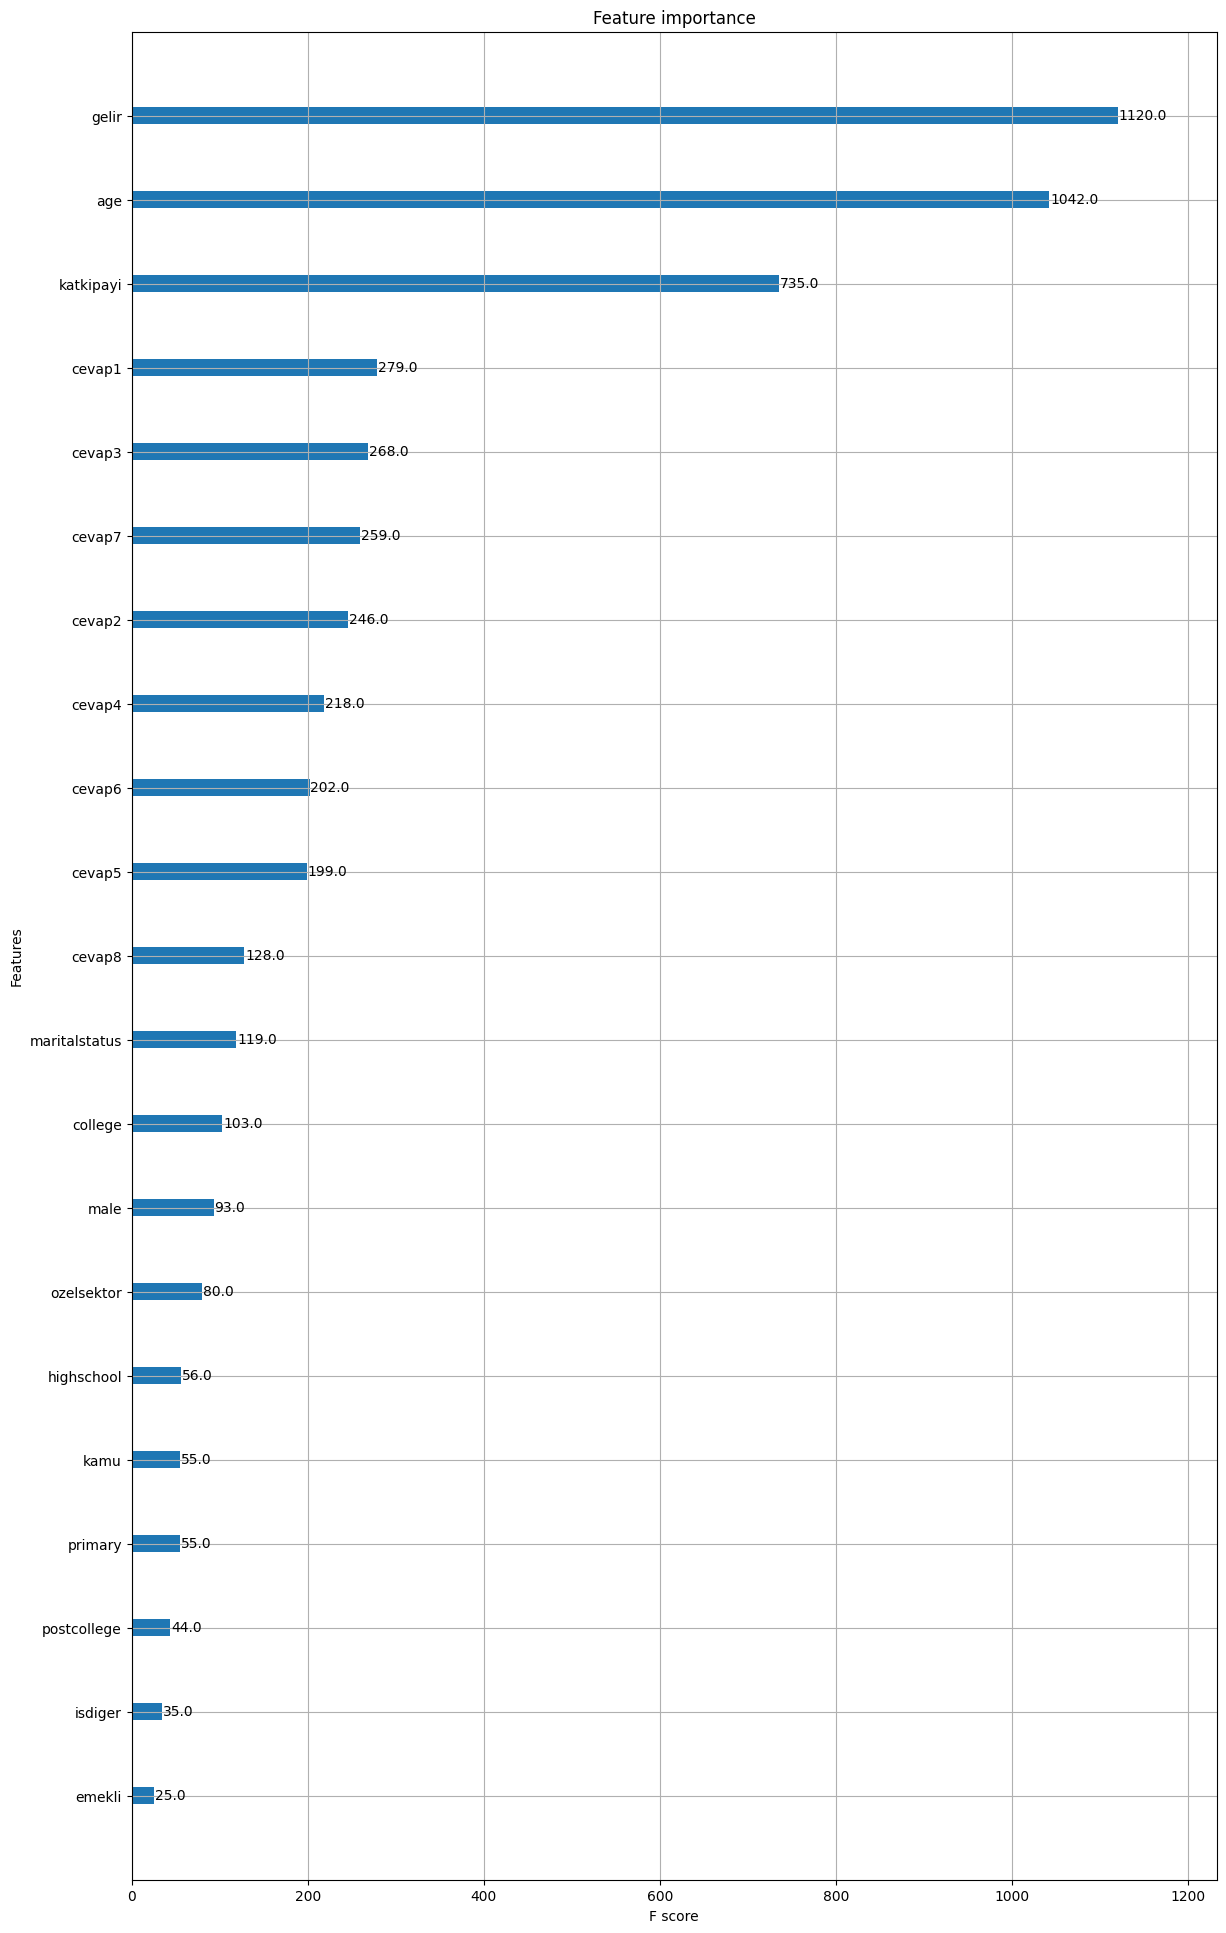

In [12]:
plt.rcParams["figure.figsize"] = (14, 24)
plot_importance(xgbr_final)
plt.show()

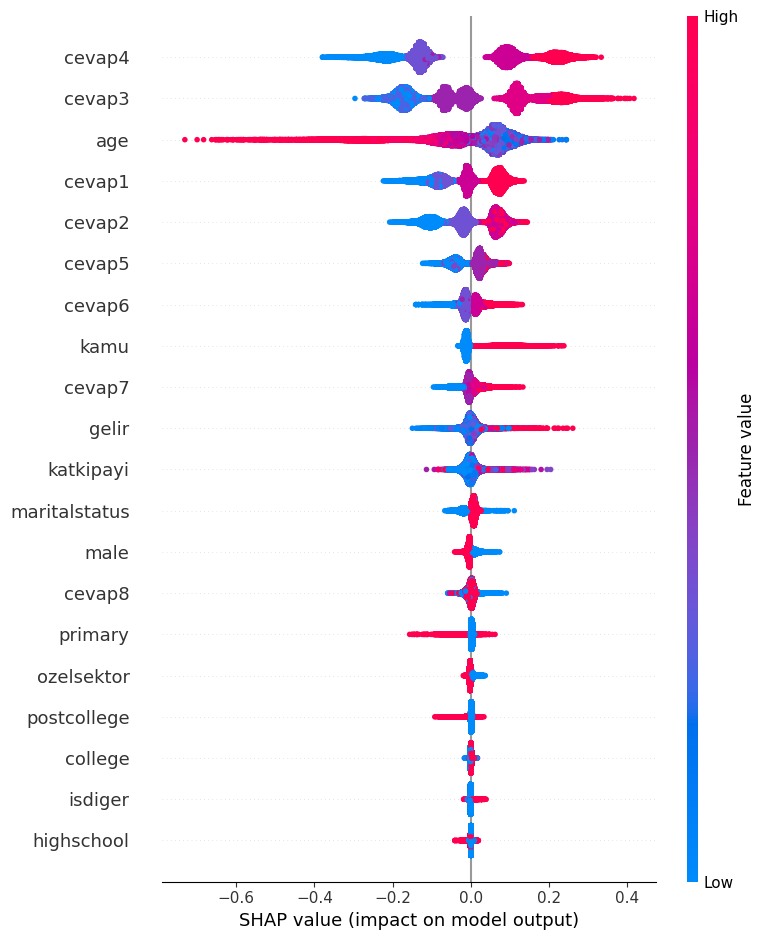

In [15]:
explainerxgbr = shap.TreeExplainer(lgbmr_final)
shap_values = explainerxgbr.shap_values(X)
shap.summary_plot(shap_values, X)

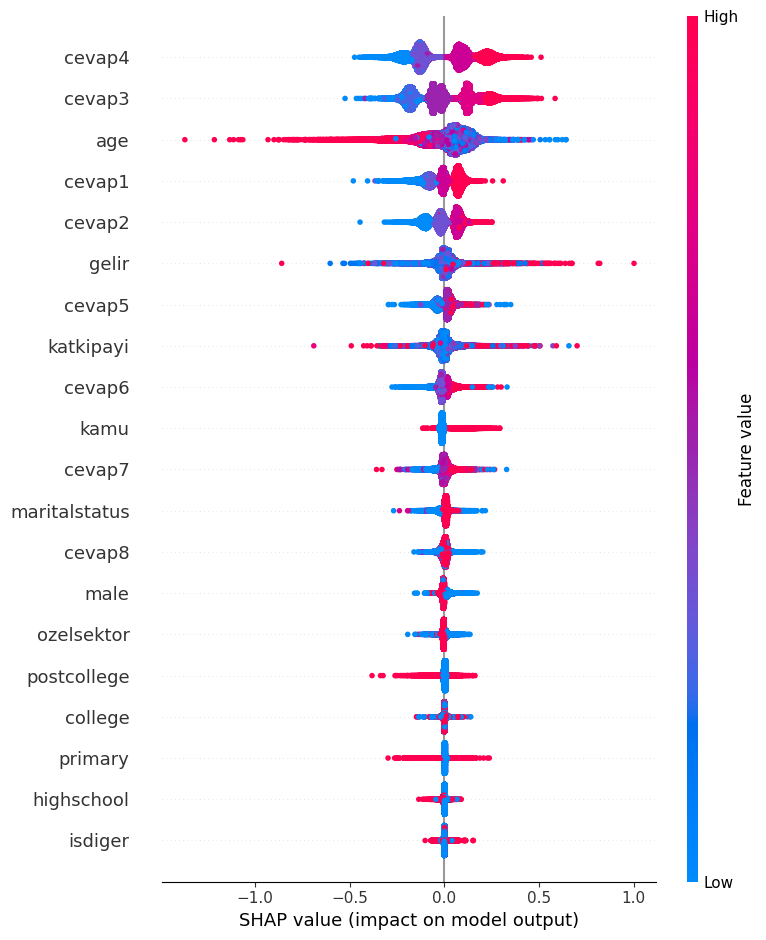

In [13]:
explainerxgbr = shap.TreeExplainer(xgbr_final)
shap_values = explainerxgbr.shap_values(X)
shap.summary_plot(shap_values, X)

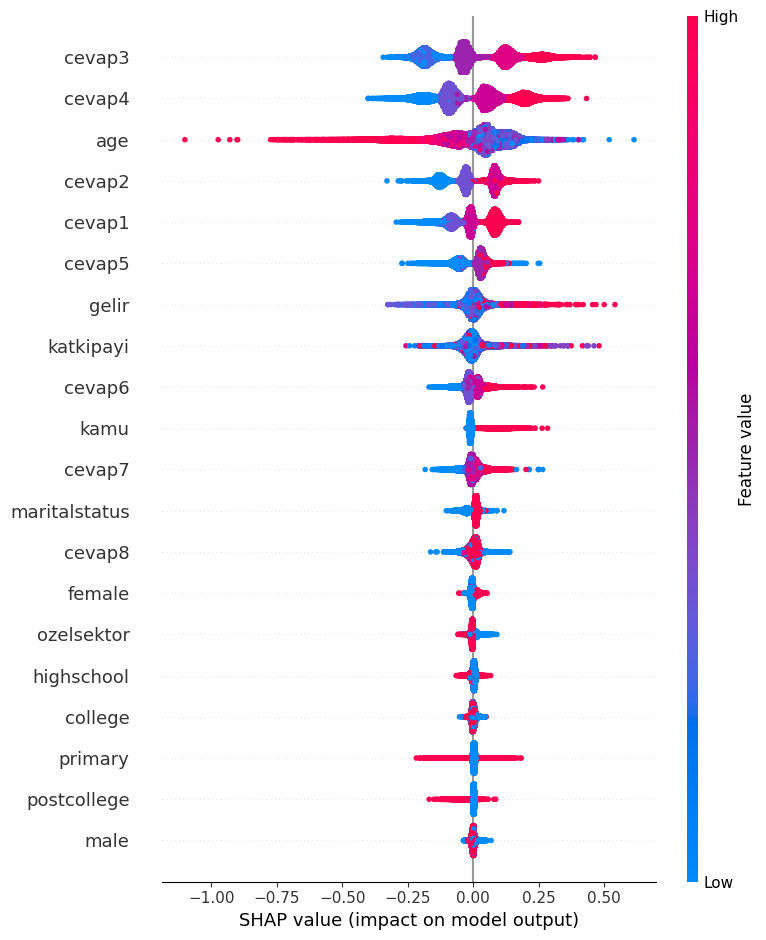

In [17]:
explainercbr = shap.TreeExplainer(cbr_final)
shap_values = explainercbr.shap_values(X)
shap.summary_plot(shap_values, X)

<h1 style="font-size:60px;"> <center> DEEP LEARNING </center> </h1>

<h1 style="font-size:40px;"> <center> Autokeras Model Search </center> </h1>

In [55]:
X_train_inner_val, X_outer_val, y_train_inner_val, y_outer_val = train_test_split(X, y, test_size=0.5, random_state=42)

callback = [
    EarlyStopping(monitor='val_loss', patience=25, mode="min"), 
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=15, verbose=1, min_delta=1e-3, mode='min')
    ]

In [56]:
search = ak.StructuredDataRegressor(
    max_trials=3,
    project_name="Credit Risk Regressor",
    loss="mean_squared_error",
    overwrite=True,
)
search.fit(
    x=X_train_inner_val,
    y=y_train_inner_val,
    epochs=30,
    verbose=2,
    callbacks=[callback],
    validation_split=0.3,
)

Trial 3 Complete [00h 02m 34s]
val_loss: 0.7368086576461792

Best val_loss So Far: 0.7368086576461792
Total elapsed time: 00h 07m 50s
INFO:tensorflow:Oracle triggered exit


INFO:tensorflow:Oracle triggered exit


Epoch 1/30
1415/1430 [============================>.] - ETA: 0s - loss: 1.0514 - mean_squared_error: 1.0514WARNING:tensorflow:Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss,mean_squared_error


1430/1430 [==============================] - 5s 3ms/step - loss: 1.0495 - mean_squared_error: 1.0495 - lr: 0.0010
Epoch 2/30
1430/1430 [==============================] - ETA: 0s - loss: 0.7864 - mean_squared_error: 0.7864WARNING:tensorflow:Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss,mean_squared_error


1430/1430 [==============================] - 5s 3ms/step - loss: 0.7864 - mean_squared_error: 0.7864 - lr: 0.0010
Epoch 3/30
1420/1430 [============================>.] - ETA: 0s - loss: 0.7632 - mean_squared_error: 0.7632WARNING:tensorflow:Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss,mean_squared_error


...

1430/1430 [==============================] - 4s 3ms/step - loss: 0.7035 - mean_squared_error: 0.7035 - lr: 0.0010
Epoch 29/30
1421/1430 [============================>.] - ETA: 0s - loss: 0.7030 - mean_squared_error: 0.7030WARNING:tensorflow:Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss,mean_squared_error


1430/1430 [==============================] - 4s 3ms/step - loss: 0.7031 - mean_squared_error: 0.7031 - lr: 0.0010
Epoch 30/30
1413/1430 [============================>.] - ETA: 0s - loss: 0.7018 - mean_squared_error: 0.7018WARNING:tensorflow:Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss,mean_squared_error


1430/1430 [==============================] - 4s 3ms/step - loss: 0.7021 - mean_squared_error: 0.7021 - lr: 0.0010


INFO:tensorflow:Assets written to: .\Credit Risk Regressor\best_model\assets


INFO:tensorflow:Assets written to: .\Credit Risk Regressor\best_model\assets


In [57]:
best_nn_model = search.export_model()
best_nn_model

<h1 style="font-size:40px;"> <center> Best NN Model Outer Validation Evaluation  </center> </h1>

In [74]:
with mlflow.start_run(experiment_id=experiment.experiment_id, run_name='AutoKeras Best Model Outer Evaluation') as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=2, shuffle=True, random_state=42)

    for train_index, val_index in tqdm(
        kf.split(X_outer_val), desc="Best NN Model Outer Validation Evaluation..."
    ):
        X_train, X_val = X_outer_val.iloc[train_index], X_outer_val.iloc[val_index]
        y_train, y_val = y_outer_val.iloc[train_index], y_outer_val.iloc[val_index]
        best_nn_model.fit(
            X_train,
            y_train,
            epochs=2,
            verbose=2,
            callbacks=[callback],
            validation_split=0.2,
        )
        y_pred = best_nn_model.predict(X_val)
        y_pred = pd.Series(y_pred.flatten())
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)
    print(
        "Ensemble Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Ensemble Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_param("layer number", len(best_nn_model.get_config()["layers"]))
    mlflow.log_param("learning rate", K.eval(best_nn_model.optimizer.lr))
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))
    mlflow.keras.log_model(best_nn_model, "Autokeras")

Best NN Model Outer Validation Evaluation...: 0it [00:00, ?it/s]

Epoch 1/2
572/572 - 2s - loss: 0.6453 - mean_squared_error: 0.6453 - val_loss: 0.6861 - val_mean_squared_error: 0.6861 - lr: 1.0000e-16 - 2s/epoch - 3ms/step
Epoch 2/2
572/572 - 2s - loss: 0.6453 - mean_squared_error: 0.6453 - val_loss: 0.6861 - val_mean_squared_error: 0.6861 - lr: 1.0000e-16 - 2s/epoch - 3ms/step
715/715 [==============================] - 2s 3ms/step


Best NN Model Outer Validation Evaluation...: 1it [00:06,  6.46s/it]

Epoch 1/2
572/572 - 2s - loss: 0.6563 - mean_squared_error: 0.6563 - val_loss: 0.6967 - val_mean_squared_error: 0.6967 - lr: 1.0000e-16 - 2s/epoch - 3ms/step
Epoch 2/2
572/572 - 2s - loss: 0.6563 - mean_squared_error: 0.6563 - val_loss: 0.6967 - val_mean_squared_error: 0.6967 - lr: 1.0000e-16 - 2s/epoch - 3ms/step
715/715 [==============================] - 2s 3ms/step


Best NN Model Outer Validation Evaluation...: 2it [00:12,  6.25s/it]


Ensemble Mean MSE Score: 0.6589290499687195, STD of MSE Score: 0.00548100471496582
Ensemble Mean R2 Score: 0.1694251151529821, STD of R2 Score: 0.005720953159530473


INFO:tensorflow:Assets written to: C:\Users\NEO\AppData\Local\Temp\tmp_htoy9go\model\data\model\assets


INFO:tensorflow:Assets written to: C:\Users\NEO\AppData\Local\Temp\tmp_htoy9go\model\data\model\assets
2022/12/28 22:04:33 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\NEO\AppData\Local\Temp\tmp_htoy9go\model, flavor: keras), fall back to return ['tensorflow==2.11.0', 'keras==2.11.0']. Set logging level to DEBUG to see the full traceback.


<h1 style="font-size:40px;"> <center> Best NN Model Full Data Evaluation  </center> </h1>

In [59]:
with mlflow.start_run(experiment_id=experiment.experiment_id, run_name='AutoKeras Best Model Full Data Evaluation') as run:
    mse_scores = []
    r2_scores = []
    kf = KFold(n_splits=10, shuffle=True, random_state=42)

    for train_index, val_index in tqdm(
        kf.split(X_outer_val), desc="AutoKeras Best Model Full Data Evaluation..."
    ):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y.iloc[train_index], y.iloc[val_index]
        best_nn_model.fit(
            X_train,
            y_train,
            epochs=50,
            verbose=2,
            callbacks=[callback],
            validation_split=0.2,
        )
        y_pred = best_nn_model.predict(X_val)
        y_pred = pd.Series(y_pred.flatten())
        mse_score = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse_score)
        r2_score_val = r2_score(y_val, y_pred)
        r2_scores.append(r2_score_val)
    print(
        "Ensemble Mean MSE Score: {}, STD of MSE Score: {}".format(
            np.mean(mse_scores), np.std(mse_scores)
        )
    )
    print(
        "Ensemble Mean R2 Score: {}, STD of R2 Score: {}".format(
            np.mean(r2_scores), np.std(r2_scores)
        )
    )
    mlflow.log_param("layer number", len(best_nn_model.get_config()["layers"]))
    mlflow.log_param("learning rate", K.eval(best_nn_model.optimizer.lr))
    mlflow.log_metric("mse", np.mean(mse_scores))
    mlflow.log_metric("r2", np.mean(r2_scores))
    mlflow.keras.log_model(best_nn_model, "Autokeras")

AutoKeras Best Model Full Data Evaluation...: 0it [00:00, ?it/s]

Epoch 1/50
1030/1030 - 3s - loss: 0.6786 - mean_squared_error: 0.6786 - val_loss: 0.6858 - val_mean_squared_error: 0.6858 - lr: 1.0000e-05 - 3s/epoch - 3ms/step
Epoch 2/50
1030/1030 - 3s - loss: 0.6781 - mean_squared_error: 0.6781 - val_loss: 0.6857 - val_mean_squared_error: 0.6857 - lr: 1.0000e-05 - 3s/epoch - 3ms/step
Epoch 3/50
1030/1030 - 3s - loss: 0.6778 - mean_squared_error: 0.6778 - val_loss: 0.6856 - val_mean_squared_error: 0.6856 - lr: 1.0000e-05 - 3s/epoch - 3ms/step
Epoch 4/50
1030/1030 - 3s - loss: 0.6774 - mean_squared_error: 0.6774 - val_loss: 0.6863 - val_mean_squared_error: 0.6863 - lr: 1.0000e-05 - 3s/epoch - 3ms/step
Epoch 5/50
1030/1030 - 3s - loss: 0.6774 - mean_squared_error: 0.6774 - val_loss: 0.6861 - val_mean_squared_error: 0.6861 - lr: 1.0000e-05 - 3s/epoch - 3ms/step
Epoch 6/50
1030/1030 - 3s - loss: 0.6771 - mean_squared_error: 0.6771 - val_loss: 0.6856 - val_mean_squared_error: 0.6856 - lr: 1.0000e-05 - 3s/epoch - 3ms/step
Epoch 7/50
1030/1030 - 3s - loss: 

143/143 [==============================] - 0s 3ms/step


AutoKeras Best Model Full Data Evaluation...: 1it [02:28, 148.06s/it]

Epoch 1/50
1030/1030 - 3s - loss: 0.6828 - mean_squared_error: 0.6828 - val_loss: 0.6813 - val_mean_squared_error: 0.6813 - lr: 1.0000e-08 - 3s/epoch - 3ms/step
Epoch 2/50
1030/1030 - 3s - loss: 0.6828 - mean_squared_error: 0.6828 - val_loss: 0.6813 - val_mean_squared_error: 0.6813 - lr: 1.0000e-08 - 3s/epoch - 3ms/step
Epoch 3/50
1030/1030 - 3s - loss: 0.6828 - mean_squared_error: 0.6828 - val_loss: 0.6813 - val_mean_squared_error: 0.6813 - lr: 1.0000e-08 - 3s/epoch - 3ms/step
Epoch 4/50
1030/1030 - 3s - loss: 0.6828 - mean_squared_error: 0.6828 - val_loss: 0.6813 - val_mean_squared_error: 0.6813 - lr: 1.0000e-08 - 3s/epoch - 3ms/step
Epoch 5/50
1030/1030 - 3s - loss: 0.6828 - mean_squared_error: 0.6828 - val_loss: 0.6813 - val_mean_squared_error: 0.6813 - lr: 1.0000e-08 - 3s/epoch - 3ms/step
Epoch 6/50
1030/1030 - 3s - loss: 0.6828 - mean_squared_error: 0.6828 - val_loss: 0.6813 - val_mean_squared_error: 0.6813 - lr: 1.0000e-08 - 3s/epoch - 3ms/step
Epoch 7/50
1030/1030 - 3s - loss: 

...

Epoch 1/50
1030/1030 - 3s - loss: 0.6762 - mean_squared_error: 0.6762 - val_loss: 0.6783 - val_mean_squared_error: 0.6783 - lr: 1.0000e-18 - 3s/epoch - 3ms/step
Epoch 2/50
1030/1030 - 3s - loss: 0.6762 - mean_squared_error: 0.6762 - val_loss: 0.6783 - val_mean_squared_error: 0.6783 - lr: 1.0000e-18 - 3s/epoch - 3ms/step
Epoch 3/50
1030/1030 - 3s - loss: 0.6762 - mean_squared_error: 0.6762 - val_loss: 0.6783 - val_mean_squared_error: 0.6783 - lr: 1.0000e-18 - 3s/epoch - 3ms/step
Epoch 4/50
1030/1030 - 3s - loss: 0.6762 - mean_squared_error: 0.6762 - val_loss: 0.6783 - val_mean_squared_error: 0.6783 - lr: 1.0000e-18 - 3s/epoch - 3ms/step
Epoch 5/50
1030/1030 - 3s - loss: 0.6762 - mean_squared_error: 0.6762 - val_loss: 0.6783 - val_mean_squared_error: 0.6783 - lr: 1.0000e-18 - 3s/epoch - 3ms/step
Epoch 6/50
1030/1030 - 3s - loss: 0.6762 - mean_squared_error: 0.6762 - val_loss: 0.6783 - val_mean_squared_error: 0.6783 - lr: 1.0000e-18 - 3s/epoch - 3ms/step
Epoch 7/50
1030/1030 - 3s - loss: 

AutoKeras Best Model Full Data Evaluation...: 10it [15:18, 91.83s/it]

Ensemble Mean MSE Score: 0.6785945296287537, STD of MSE Score: 0.017327193170785904
Ensemble Mean R2 Score: 0.14932611235831844, STD of R2 Score: 0.01033354186017864


INFO:tensorflow:Assets written to: C:\Users\NEO\AppData\Local\Temp\tmpwph08p37\model\data\model\assets


INFO:tensorflow:Assets written to: C:\Users\NEO\AppData\Local\Temp\tmpwph08p37\model\data\model\assets
2022/12/29 12:16:45 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\NEO\AppData\Local\Temp\tmpwph08p37\model, flavor: keras), fall back to return ['tensorflow==2.11.0', 'keras==2.11.0']. Set logging level to DEBUG to see the full traceback.


<h1 style="font-size:40px;"> <center> Best NN Model Summary & Save  </center> </h1>

In [60]:
best_nn_model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 22)]              0         
                                                                 
 multi_category_encoding (Mu  (None, 22)               0         
 ltiCategoryEncoding)                                            
                                                                 
 dense (Dense)               (None, 32)                736       
                                                                 
 re_lu (ReLU)                (None, 32)                0         
                                                                 
 dense_1 (Dense)             (None, 32)                1056      
                                                                 
 re_lu_1 (ReLU)              (None, 32)                0         
                                                             

In [61]:
tf.keras.utils.plot_model(best_nn_model, show_shapes=True, expand_nested=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [ ]:
path_directory = "C:/Users/NEO/Desktop/Projects/Credit Risk/Best Auto Keras Model"
try:
    best_nn_model.save(os.path.join(path_directory, "best_autokeras_model"), save_format="tf")
except Exception:
    best_nn_model.save(os.path.join(path_directory, "best_autokeras_model.h5"))